# 07b Plot extreme temperature distributions

In [79]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import xarray as xr
import pandas as pd
import netCDF4 as nc
import numpy as np
from dask.distributed import Client
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sys.path.append('/home/563/sc1326/repos/cdrmip_extremes')
from cdrmip_extremes.configs import data_dir, models, expts
from cdrmip_extremes import load_data, ext_freq
from cdrmip_extremes.plotting import plot_extremes

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [80]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

## Load Data

In [81]:
ext_freq_data = load_data.load_ext_freq_data()

In [90]:
ext_month_tas = load_data.load_ext_month_tas(period='gwls_anom',final=False)

In [83]:
thresholds = load_data.load_threshold_data()

In [84]:
areacella, mask_land, mask_ocean = load_data.load_fx()
mask_land, mask_ocean = mask_land.topo, mask_ocean.topo

## Plot distributions

In [8]:
# to_plot = defaultdict(dict)
# for ext_type in ['heat','cold']:
#     ds_up = ext_freq_data['Multi-Model Median'][f'{ext_type}_exceedances'].sel(gwl=1.5,branch='ramp_up')
#     ds_down = ext_freq_data['Multi-Model Median'][f'{ext_type}_exceedances'].sel(gwl=1.5,branch='ramp_down')
    
#     ds_up_land, ds_down_land = ds_up*mask_ocean, ds_down*mask_ocean
#     ds_up_ocean, ds_down_ocean = ds_up*mask_land, ds_down*mask_land


In [85]:
def flatten_weighted(da):
    weights = np.cos(np.deg2rad(da.lat))
    weights2d = weights.broadcast_like(da)
    vals = da.values.flatten()
    w = weights2d.values.flatten()
    mask = ~np.isnan(vals)
    return vals[mask], w[mask]

titles = {
    'heat': {
        'sigma1':'1$\sigma$',
        'sigma2':'2$\sigma$',
        'sigma3':'3$\sigma$'
    },
    'cold':{
        'sigma1':'-0.25$\sigma$',
        'sigma2':'-0.5$\sigma$',
        'sigma3':'-1$\sigma$'
    }
}

In [72]:
def plot_ext_freq_distribution(ext_freq_data,model,ext_type,gwl,surface,mask=None):
    ds_up = ext_freq_data[model][f'{ext_type}_exceedances'].sel(gwl=gwl,branch='ramp_up')
    ds_down = ext_freq_data[model][f'{ext_type}_exceedances'].sel(gwl=gwl,branch='ramp_down')

    if mask is not None:
        ds_up = ds_up * mask
        ds_down = ds_down * mask
    
    fig, axes = plt.subplots(1,3,figsize=(16,5))

    for threshold, ax in zip(['sigma1','sigma2','sigma3'],axes.flat):
    
        vals1, w1 = flatten_weighted(ds_up[threshold])
        vals2, w2 = flatten_weighted(ds_down[threshold])
        
        sns.kdeplot(
            ax=ax,
            x=vals1,
            weights=w1,
            label="ramp-up",
            fill=True,
            color='red',
            alpha=0.3
        )
        sns.kdeplot(
            ax=ax,
            x=vals2,
            weights=w2,
            label="ramp-down",
            fill=True,
            color='blue',
            alpha=0.3
        )
        
        ax.set_xlabel("Percentage of Years",fontsize=16)
        ax.set_ylabel("Density",fontsize=16)
        ax.set_yticks([])
        x_ticks = [0,20,40,60,80,100]
        ax.set_xticks(x_ticks)
        ax.set_xticklabels([str(i) for i in x_ticks],fontsize=16)
    
        ax.set_title(titles[ext_type][threshold],fontsize=24)
    axes[2].legend(fontsize=16,frameon=False)
    fig.suptitle(
        f"{model} {ext_type} extreme frequency grid-cell distributions at {gwl}°C ({surface.capitalize()})",
        fontsize=24,
        y=1.02
    )
    fig.tight_layout()
    plt.show()

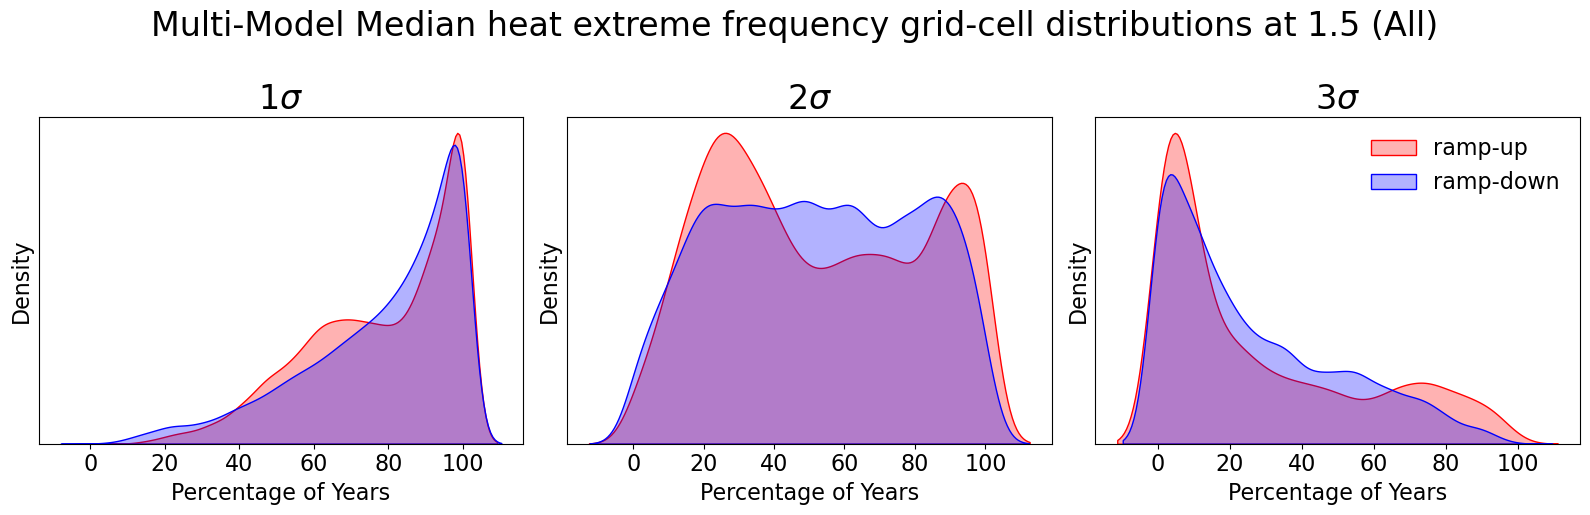

In [73]:
plot_ext_freq_distribution(
    ext_freq_data,
    'Multi-Model Median',
    'heat',
    1.5,
    'all'
)

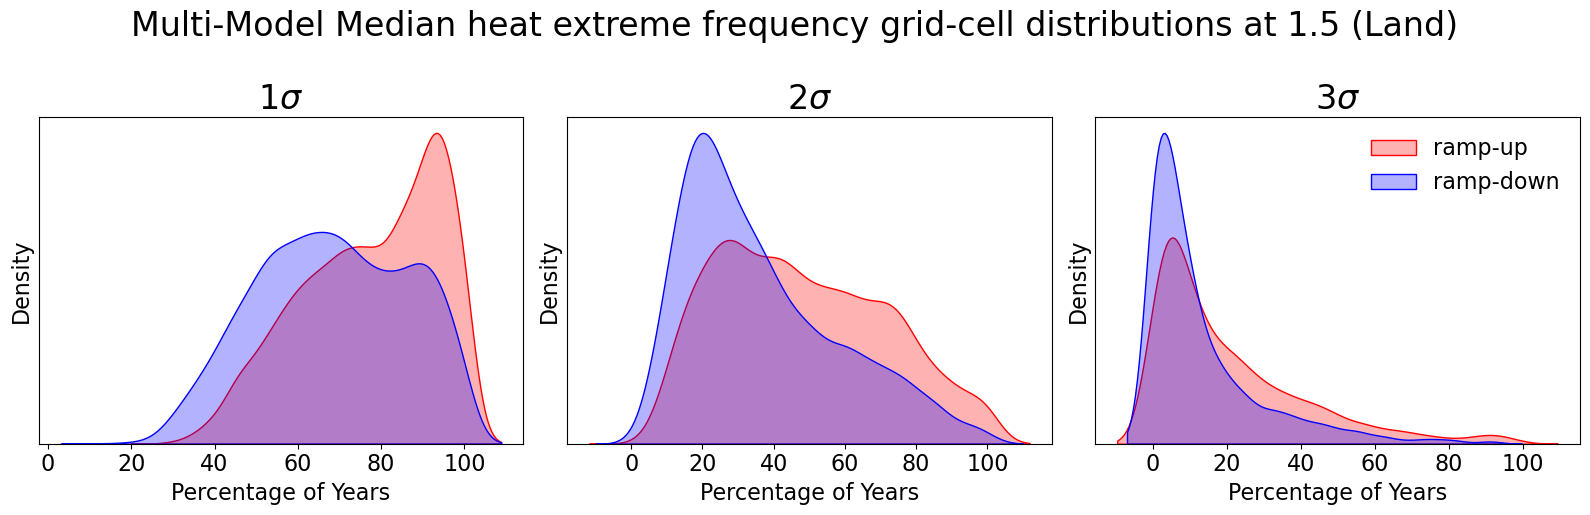

In [74]:
plot_ext_freq_distribution(
    ext_freq_data,
    'Multi-Model Median',
    'heat',
    1.5,
    'land',
    mask=mask_ocean,
)

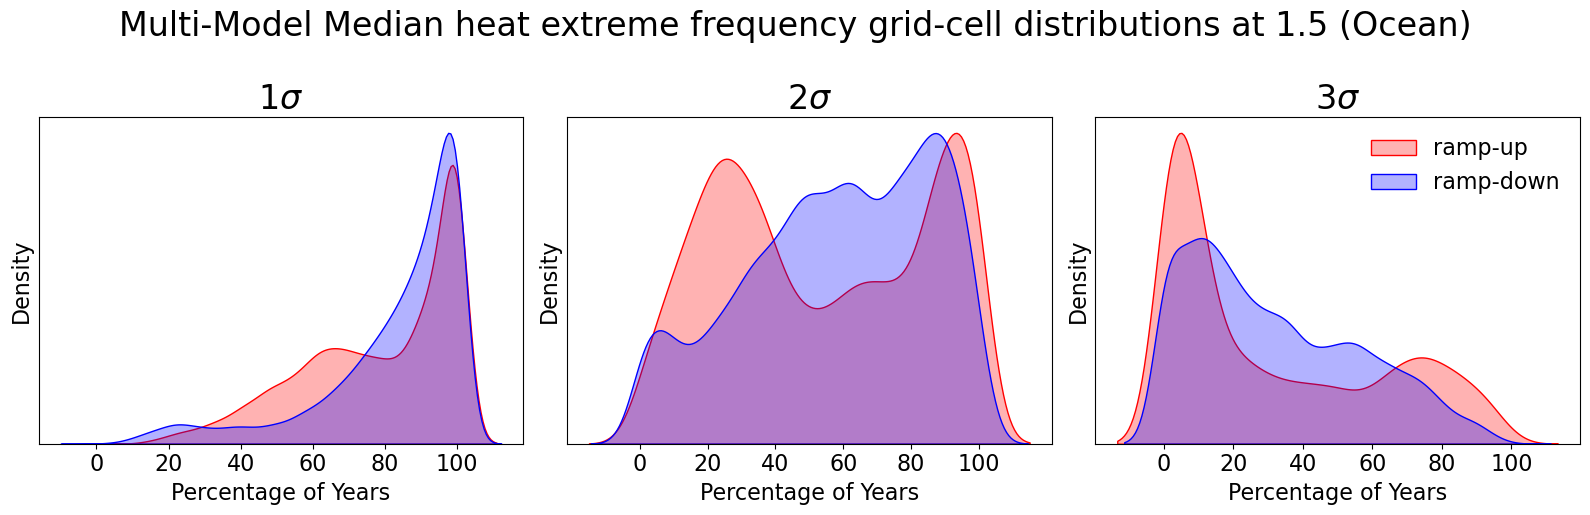

In [75]:
plot_ext_freq_distribution(
    ext_freq_data,
    'Multi-Model Median',
    'heat',
    1.5,
    'ocean',
    mask=mask_land,
)

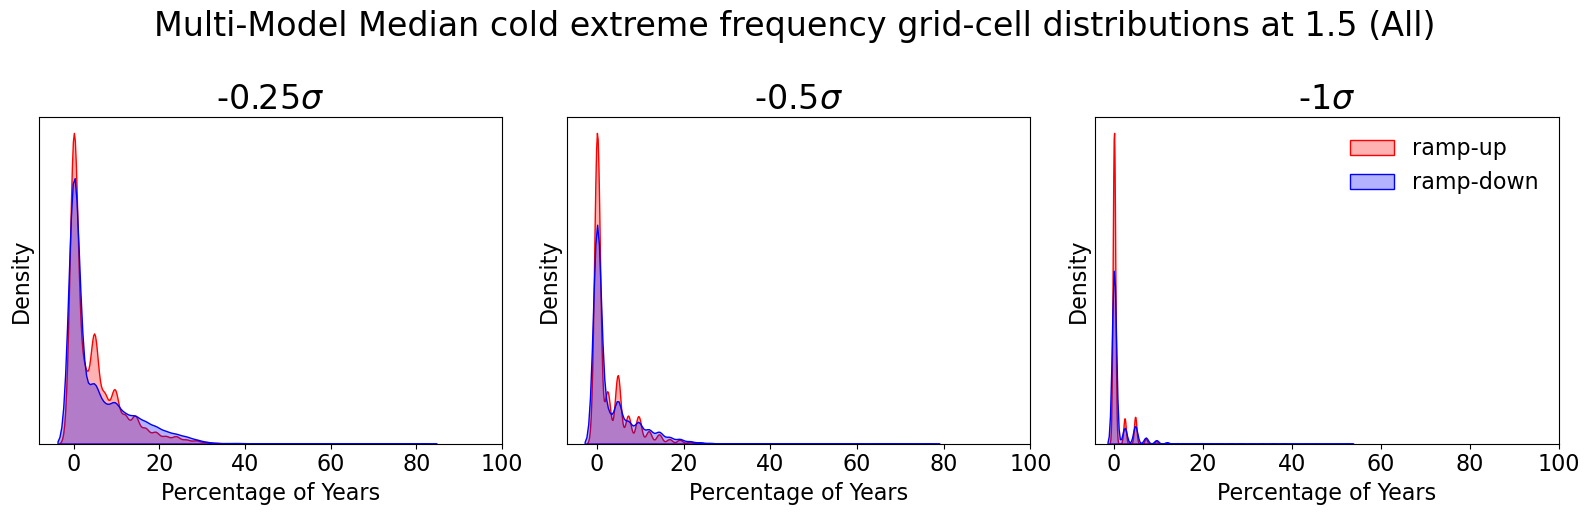

In [76]:
plot_ext_freq_distribution(
    ext_freq_data,
    'Multi-Model Median',
    'cold',
    1.5,
    'all',
    mask=None,
)

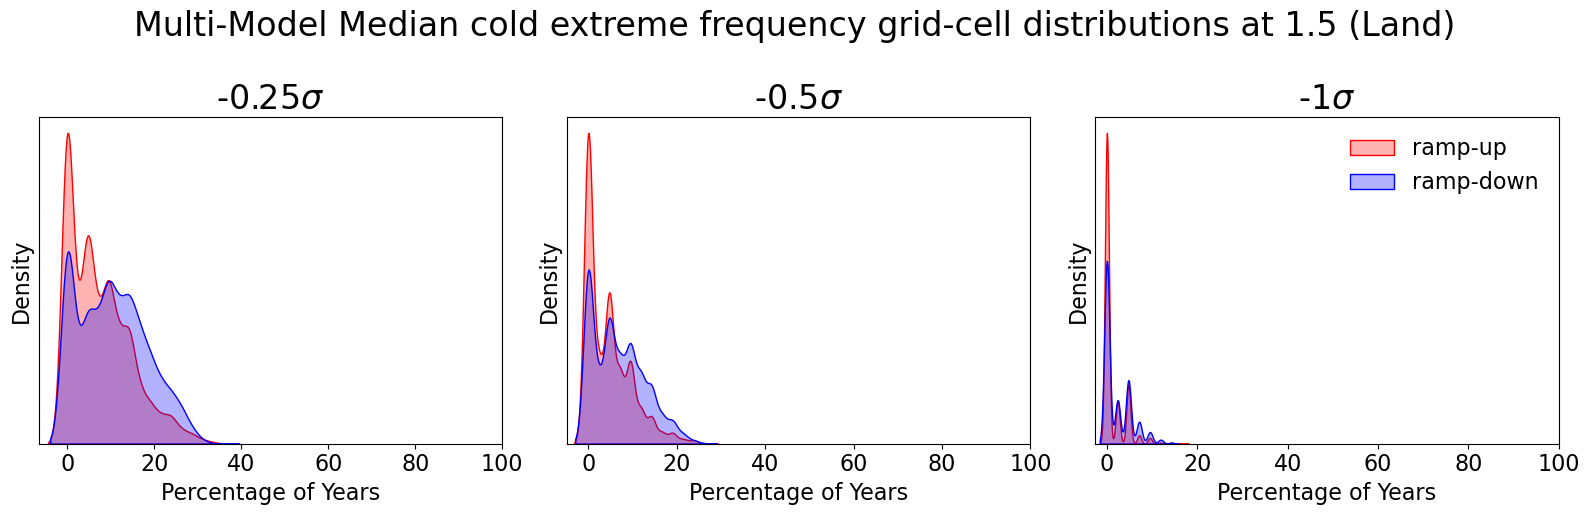

In [77]:
plot_ext_freq_distribution(
    ext_freq_data,
    'Multi-Model Median',
    'cold',
    1.5,
    'land',
    mask=mask_ocean,
)

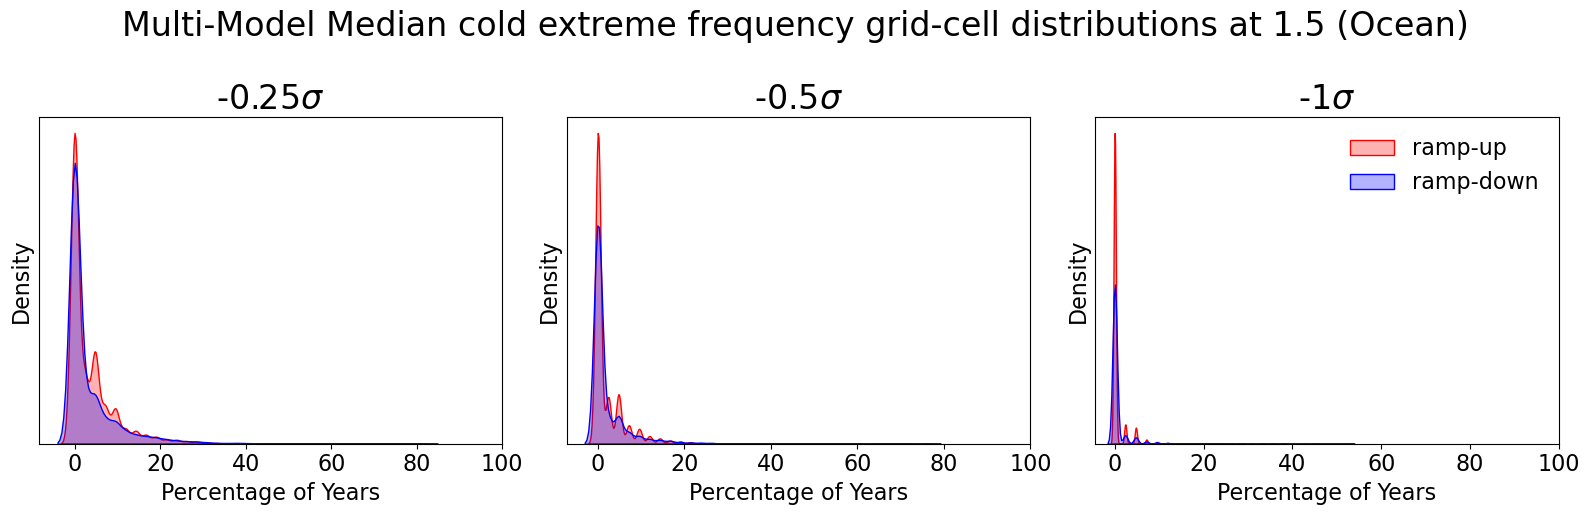

In [78]:
plot_ext_freq_distribution(
    ext_freq_data,
    'Multi-Model Median',
    'cold',
    1.5,
    'ocean',
    mask=mask_land,
)

## And for month of max/min temperatures

In [92]:
ext_month_tas['Multi-Model Median'] = xr.concat(
    ext_month_tas.values(),
    dim='model'
).median(dim='model')

In [93]:
ext_month_tas

{'ACCESS-ESM1-5': <xarray.Dataset> Size: 86MB
 Dimensions:  (branch: 2, gwl: 3, extrema: 2, year: 111, lat: 90, lon: 180)
 Coordinates:
   * branch   (branch) <U9 72B 'ramp_up' 'ramp_down'
   * gwl      (gwl) float64 24B 1.5 2.0 3.0
   * extrema  (extrema) <U4 32B 'heat' 'cold'
   * year     (year) int64 888B 51 52 53 54 55 56 57 ... 266 267 268 269 270 271
   * lat      (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 83.0 85.0 87.0 89.0
   * lon      (lon) float64 1kB 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
 Data variables:
     tas      (branch, gwl, extrema, year, lat, lon) float32 86MB ...,
 'CanESM5': <xarray.Dataset> Size: 85MB
 Dimensions:  (branch: 2, gwl: 3, extrema: 2, year: 109, lat: 90, lon: 180)
 Coordinates:
   * branch   (branch) <U9 72B 'ramp_up' 'ramp_down'
   * gwl      (gwl) float64 24B 1.5 2.0 3.0
   * extrema  (extrema) <U4 32B 'heat' 'cold'
   * year     (year) int64 872B 39 40 41 42 43 44 45 ... 288 289 290 291 292 293
   * lat      (lat) float64 720B -89.

In [113]:
def plot_ext_month_tas_distribution(ext_month_tas,model,ext_type,gwl,surface,mask=None):
    ds_up = ext_month_tas[model].sel(extrema=ext_type,gwl=gwl,branch='ramp_up').tas
    ds_down = ext_month_tas[model].sel(extrema=ext_type,gwl=gwl,branch='ramp_down').tas

    if mask is not None:
        ds_up = ds_up * mask
        ds_down = ds_down * mask
    
    fig, ax = plt.subplots(1,1,figsize=(5,5))
    
    vals1, w1 = flatten_weighted(ds_up)
    vals2, w2 = flatten_weighted(ds_down)
    
    sns.kdeplot(
        ax=ax,
        x=vals1,
        weights=w1,
        label="ramp-up",
        fill=True,
        color='red',
        alpha=0.3
    )
    sns.kdeplot(
        ax=ax,
        x=vals2,
        weights=w2,
        label="ramp-down",
        fill=True,
        color='blue',
        alpha=0.3
    )
    
    ax.set_xlabel("SAT Anomaly (°C)",fontsize=16)
    ax.set_ylabel("Density",fontsize=16)
    ax.set_yticks([])
    # ax.set_xlim([-3,35])
    # ax.set_xticks(x_ticks)
    # ax.set_xticklabels([str(i) for i in x_ticks],fontsize=16)
    ax.legend(fontsize=16,frameon=False)
    fig.suptitle(
        f"{model} {ext_type} extreme intensity grid-cell distributions at {gwl}°C ({surface.capitalize()})",
        fontsize=24,
        y=1.02
    )
    fig.tight_layout()
    plt.show()

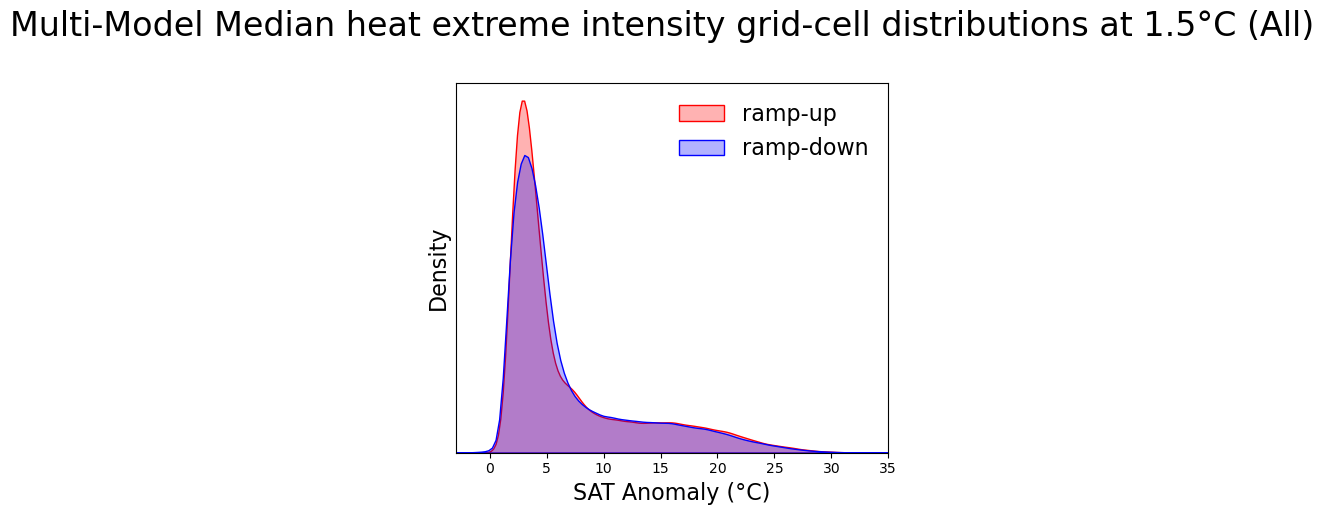

In [112]:
plot_ext_month_tas_distribution(
    ext_month_tas,
    'Multi-Model Median',
    'heat',
    1.5,
    'all',
)